In [1]:
!pip install pyserial

Acquisition terminée.
Nombre de mesures : 116
Premières valeurs brutes : [-25161, -25180, -25153, -25181, -25257, -25277, -25228, -25208, -25215, -25188]


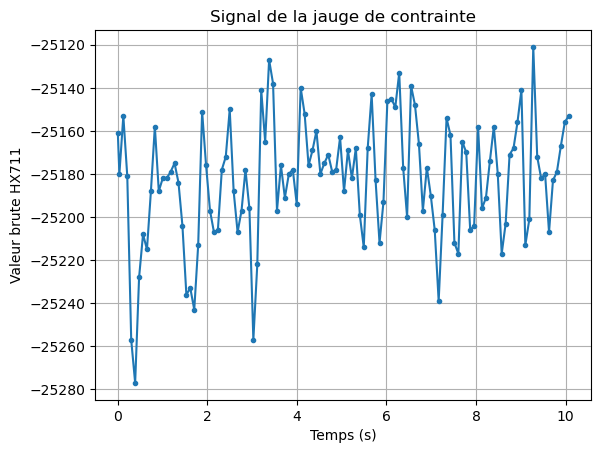

In [5]:
import serial
import time
import matplotlib.pyplot as plt

# --- Configuration du port série ---
PORT = 'COM8'          # à vérifier dans le Gestionnaire de périphériques
BAUDRATE = 115200      # même valeur que sur l'Arduino
DUREE = 10             # durée d'acquisition en secondes

serialPort = serial.Serial()
serialPort.port = PORT
serialPort.baudrate = BAUDRATE
serialPort.bytesize = serial.EIGHTBITS
serialPort.parity = serial.PARITY_NONE
serialPort.stopbits = serial.STOPBITS_ONE
serialPort.timeout = 1

serialPort.open()

# Laisser l'Arduino redémarrer et se stabiliser
time.sleep(2)
serialPort.reset_input_buffer()

# Commande de démarrage
serialPort.write(b'r')
serialPort.flush()

times = []
raw_values = []

startTime = time.time()

# --- Acquisition ---
while (time.time() - startTime) < DUREE:
    line = serialPort.readline().decode('ascii', errors='ignore').strip()

    if line:
        try:
            values = line.split(';')
            temps = float(values[0])
            valeurBrute = int(values[1])

            times.append(temps)
            raw_values.append(valeurBrute)

        except (ValueError, IndexError):
            # Ignorer les lignes qui ne sont pas des mesures
            pass

# --- Arrêt et fermeture ---
serialPort.write(b's')
serialPort.flush()
serialPort.close()

# --- Résultats ---
print("Acquisition terminée.")
print("Nombre de mesures :", len(raw_values))
print("Premières valeurs brutes :", raw_values[:10])

plt.figure()
plt.plot(times, raw_values, '.-')
plt.xlabel("Temps (s)")
plt.ylabel("Valeur brute HX711")
plt.title("Signal de la jauge de contrainte")
plt.grid(True)
plt.show()

In [21]:
import os
from datetime import datetime

dossier = r"C:\Users\polra\Desktop\codeManagementGIT\Essai"
os.makedirs(dossier, exist_ok=True)   # crée le dossier s'il n'existe pas

nom = os.path.join(dossier, datetime.now().strftime("essai_%Y%m%d_%H%M%S.txt"))

with open(nom, "w", encoding="utf-8") as f:
    f.write("temps_s;valeur\n")
    for t, v in zip(times, raw_values):
        f.write(f"{t:.4f};{v}\n")

print(f"{len(times)} mesures enregistrées dans {nom}")

116 mesures enregistrées dans C:\Users\polra\Desktop\codeManagementGIT\Essai\essai_20261117_105021.txt


In [25]:
import os
import time
import serial
from datetime import datetime

# --- Paramètres à adapter ---
PORT = "COM8"          # voir Outils > Port dans l'IDE Arduino
BAUD = 115200          # identique au Serial.begin() du sketch
N_ESSAIS = 2          # nombre d'essais (mets 2 pour tester)
DUREE = 5           # durée d'un essai en secondes (mets 5 pour tester)
DOSSIER = r"C:\Users\polra\Desktop\codeManagementGIT\Essai"

os.makedirs(DOSSIER, exist_ok=True)
session = datetime.now().strftime("%Y%m%d_%H%M%S")   # même horodatage pour toute la série


def ouvrir_port(tentatives=10):
    """Ouvre le port, avec plusieurs tentatives (le port peut disparaître après un reset)."""
    for _ in range(tentatives):
        try:
            ser = serial.Serial(PORT, BAUD, timeout=1)
            time.sleep(2)                 # laisse l'Arduino démarrer
            return ser
        except serial.SerialException:
            time.sleep(1)
    raise RuntimeError(f"Impossible d'ouvrir {PORT}")


def attendre_pret(ser, timeout=10):
    """Cherche le message 'Arduino pret'. Si absent, on continue quand même."""
    t0 = time.time()
    while time.time() - t0 < timeout:
        ligne = ser.readline().decode("utf-8", errors="ignore").strip()
        if "pret" in ligne:
            return True
    print("Message 'Arduino pret' non vu, on continue quand même.")
    return False


def faire_essai(ser, numero):
    times, raw_values = [], []
    nom = os.path.join(DOSSIER, f"essai_{numero:02d}_{session}.txt")

    ser.write(b"r")                       # démarre l'acquisition
    t0 = time.time()

    with open(nom, "w", encoding="utf-8") as f:
        f.write("temps_s;valeur\n")
        while time.time() - t0 < DUREE:
            ligne = ser.readline().decode("utf-8", errors="ignore").strip()
            if not ligne:
                continue
            try:
                if ";" in ligne:                      # format "temps_ms;valeur"
                    t_ms, v = ligne.split(";")
                    t, v = float(t_ms) / 1000, float(v)
                else:                                 # format "valeur" seule
                    t, v = time.time() - t0, float(ligne)
            except ValueError:
                continue                              # ignore les lignes de texte
            times.append(t)
            raw_values.append(v)
            f.write(f"{t:.4f};{v}\n")
            f.flush()
    return times, raw_values, nom


# --- Série d'essais ---
resultats = []
ser = ouvrir_port()
try:
    for i in range(1, N_ESSAIS + 1):
        attendre_pret(ser)
        input(f"Essai {i}/{N_ESSAIS} : appuie sur Entrée pour démarrer")
        ser.reset_input_buffer()
        times, raw_values, nom = faire_essai(ser, i)
        resultats.append((times, raw_values))
        print(f"Essai {i} : {len(times)} mesures -> {nom}")

        if i < N_ESSAIS:
            ser.write(b"R")               # reset logiciel de l'Arduino
            time.sleep(0.5)
            ser.close()
            time.sleep(10)                # redémarrage
            ser = ouvrir_port()
except KeyboardInterrupt:
    print("Arrêt manuel")
finally:
    if ser.is_open:
        ser.close()

print(f"{len(resultats)} essais enregistrés dans {DOSSIER}")

RuntimeError: Impossible d'ouvrir COM8